# Exploratory Data Analysis of the Ames Housing Dataset
**Dataset:** Kaggle *House Prices: Advanced Regression Techniques* (`train.csv`, ~1,460 rows x 81 columns)
**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn, SciPy
**Objective:** Use EDA only (no machine learning) to understand what drives house sale prices.

## Guiding questions
1. How is `SalePrice` distributed? Is it skewed?
2. Which numerical features correlate most strongly with `SalePrice`?
3. Does `OverallQual` change price in a clear, ordered way?
4. Do some neighborhoods consistently cost more than others?
5. Are there outliers, and are they errors or real but unusual sales?
6. Which columns have missing values, and which of those are not truly missing?

**How to run:** Download `train.csv` from Kaggle (competition: house-prices-advanced-regression-techniques), then run the cells top to bottom. The first code cell will ask you to upload the file.

## 1. Data loading (Step 1)
**Doing:** load the data, check shape, types and missing values.

In [ ]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import warnings; warnings.filterwarnings('ignore')

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)

# Upload train.csv (Colab). If the file already exists, skip the upload.
import os
if not os.path.exists('train.csv'):
    from google.colab import files
    files.upload()          # choose train.csv

df = pd.read_csv('train.csv')
print('Shape:', df.shape)
df.head()

Shape: (1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

In [ ]:
missing = df.isnull().sum().sort_values(ascending=False)
missing = missing[missing > 0]
missing_df = pd.DataFrame({'missing': missing, 'percent': (missing / len(df) * 100).round(2)})
print('Columns with missing values:', len(missing_df))
missing_df

Columns with missing values: 19


,missing,percent
PoolQC,1453,99.52
MiscFeature,1406,96.30
Alley,1369,93.77
Fence,1179,80.75
MasVnrType,872,59.73
FireplaceQu,690,47.26
LotFrontage,259,17.74
GarageQual,81,5.55
GarageFinish,81,5.55
GarageType,81,5.55


**What I learned :** The dataset has 1,460 rows and 81 columns. 19 columns have missing values. The biggest gaps are in `PoolQC` (99.5%), `MiscFeature` (96.3%), `Alley` (93.8%) and `Fence` (80.8%). These look like "feature absent" rather than unknown, which is checked in Step 9.

## 2. Data understanding: classify variables (Step 2)
**Doing:** split columns into numerical, categorical, ordinal.

In [ ]:
numeric_cols = df.select_dtypes(include='number').columns.tolist()
categorical_cols = df.select_dtypes(include='object').columns.tolist()

# Ordinal columns -> ordered categoricals
order = ['Po', 'Fa', 'TA', 'Gd', 'Ex']
ordinal_map = {'ExterQual': order, 'KitchenQual': order}
for col, cats in ordinal_map.items():
    df[col] = pd.Categorical(df[col], categories=cats, ordered=True)

summary = pd.DataFrame({
    'column': df.columns,
    'type': ['ordinal' if c in ordinal_map or c == 'OverallQual'
             else 'numerical' if c in numeric_cols else 'categorical' for c in df.columns],
    'unique_values': [df[c].nunique() for c in df.columns],
    'example_values': [df[c].dropna().unique()[:3].tolist() for c in df.columns],
})
summary

,column,type,unique_values,example_values
0,Id,numerical,1460,"[1, 2, 3]"
1,MSSubClass,numerical,15,"[60, 20, 70]"
2,MSZoning,categorical,5,"[RL, RM, C (all)]"
3,LotFrontage,numerical,110,"[65.0, 80.0, 68.0]"
4,LotArea,numerical,1073,"[8450, 9600, 11250]"
...,...,...,...,...
76,MoSold,numerical,12,"[2, 5, 9]"
77,YrSold,numerical,5,"[2008, 2007, 2006]"
78,SaleType,categorical,9,"[WD, New, COD]"
79,SaleCondition,categorical,6,"[Normal, Abnorml, Partial]"


**Note:** `OverallQual` (1 to 10) is stored as a number but is really **ordinal**: the gap between quality 4 and 5 is not necessarily the same as between 8 and 9. `ExterQual` and `KitchenQual` are ordinal too (Po < Fa < TA < Gd < Ex).

## 3. Descriptive statistics (Step 3)
**Doing:** centre and spread of `SalePrice`, `GrLivArea`, `LotArea`.

In [ ]:
display(df[numeric_cols].describe().T)

rows = []
for c in ['SalePrice', 'GrLivArea', 'LotArea']:
    s = df[c]
    rows.append({
        'column': c, 'mean': s.mean(), 'median': s.median(), 'mode': s.mode()[0],
        'std': s.std(), 'variance': s.var(), 'range': s.max() - s.min(),
        'IQR': s.quantile(.75) - s.quantile(.25),
        'skew': stats.skew(s), 'kurtosis': stats.kurtosis(s),
        'shape': 'right skewed' if s.mean() > s.median() else 'left skewed' if s.mean() < s.median() else 'symmetric',
    })
pd.DataFrame(rows).set_index('column').round(2)

,count,mean,std,min,25%,50%,75%,max
Id,1460.0,730.500000,421.610009,1.0,365.75,730.5,1095.25,1460.0
MSSubClass,1460.0,56.897260,42.300571,20.0,20.00,50.0,70.00,190.0
LotFrontage,1201.0,70.049958,24.284752,21.0,59.00,69.0,80.00,313.0
LotArea,1460.0,10516.828082,9981.264932,1300.0,7553.50,9478.5,11601.50,215245.0
OverallQual,1460.0,6.099315,1.382997,1.0,5.00,6.0,7.00,10.0
OverallCond,1460.0,5.575342,1.112799,1.0,5.00,5.0,6.00,9.0
YearBuilt,1460.0,1971.267808,30.202904,1872.0,1954.00,1973.0,2000.00,2010.0
YearRemodAdd,1460.0,1984.865753,20.645407,1950.0,1967.00,1994.0,2004.00,2010.0
MasVnrArea,1452.0,103.685262,181.066207,0.0,0.00,0.0,166.00,1600.0
BsmtFinSF1,1460.0,443.639726,456.098091,0.0,0.00,383.5,712.25,5644.0


,mean,median,mode,std,variance,range,IQR,skew,kurtosis,shape
column,,,,,,,,,,
SalePrice,180921.20,163000.0,140000,79442.50,6.311111e+09,720100,84025.00,1.88,6.51,right skewed
GrLivArea,1515.46,1464.0,864,525.48,2.761296e+05,5308,647.25,1.37,4.87,right skewed
LotArea,10516.83,9478.5,7200,9981.26,9.962565e+07,213945,4048.00,12.20,202.54,right skewed


In [ ]:
for c in ['Neighborhood', 'HouseStyle']:
    print(df[c].value_counts(), '\nMode:', df[c].mode()[0], '\n')

Neighborhood
NAmes      225
CollgCr    150
OldTown    113
Edwards    100
Somerst     86
Gilbert     79
NridgHt     77
Sawyer      74
NWAmes      73
SawyerW     59
BrkSide     58
Crawfor     51
Mitchel     49
NoRidge     41
Timber      38
IDOTRR      37
ClearCr     28
SWISU       25
StoneBr     25
Blmngtn     17
MeadowV     17
BrDale      16
Veenker     11
NPkVill      9
Blueste      2
Name: count, dtype: int64 
Mode: NAmes 

HouseStyle
1Story    726
2Story    445
1.5Fin    154
SLvl       65
SFoyer     37
1.5Unf     14
2.5Unf     11
2.5Fin      8
Name: count, dtype: int64 
Mode: 1Story 



**Interpretation:** For `SalePrice`, the mean is higher than the median. This means a small number of very expensive houses pull the mean upward, so the distribution is **right skewed** and the median is a better 'typical price'.

## 4. Univariate analysis: distributions (Step 4)

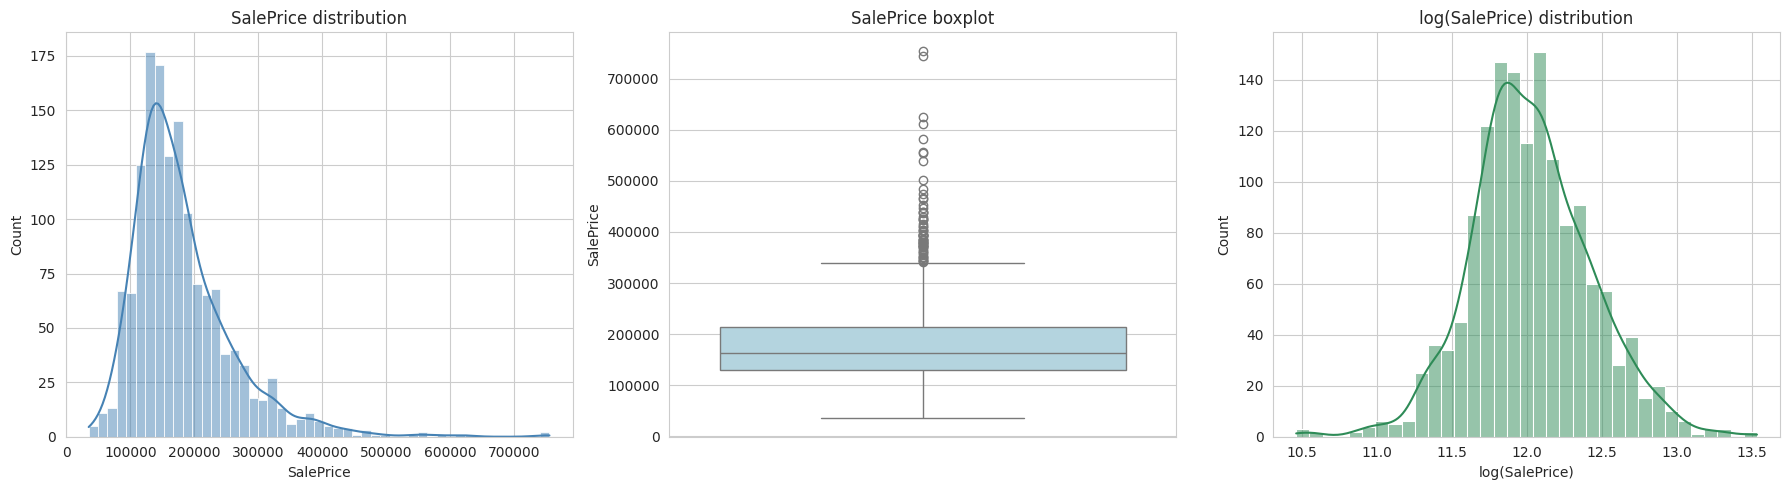

Skewness before log: 1.881
Skewness after log : 0.121


In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
sns.histplot(df['SalePrice'], kde=True, ax=ax[0], color='steelblue')
ax[0].set(title='SalePrice distribution', xlabel='SalePrice', ylabel='Count')
sns.boxplot(y=df['SalePrice'], ax=ax[1], color='lightblue')
ax[1].set(title='SalePrice boxplot', ylabel='SalePrice')
sns.histplot(np.log(df['SalePrice']), kde=True, ax=ax[2], color='seagreen')
ax[2].set(title='log(SalePrice) distribution', xlabel='log(SalePrice)', ylabel='Count')
plt.tight_layout(); plt.show()

print('Skewness before log:', round(stats.skew(df['SalePrice']), 3))
print('Skewness after log :', round(stats.skew(np.log(df['SalePrice'])), 3))

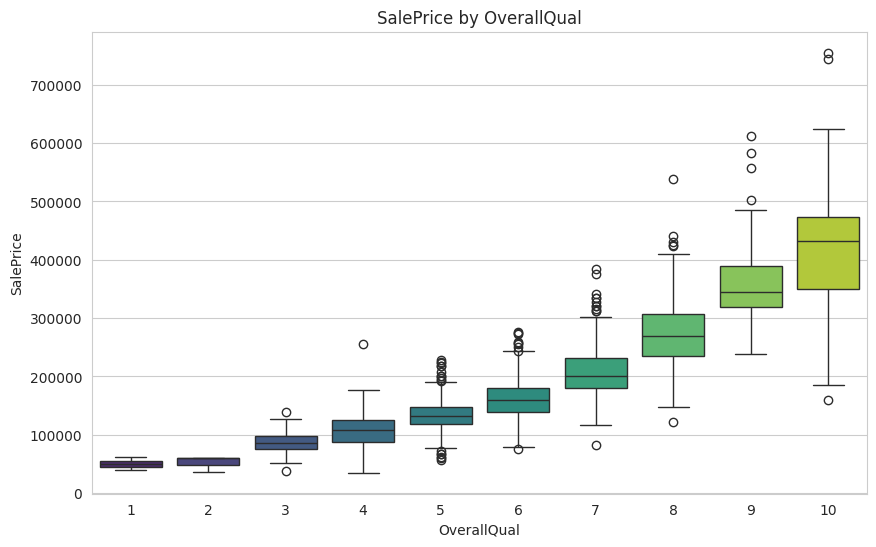

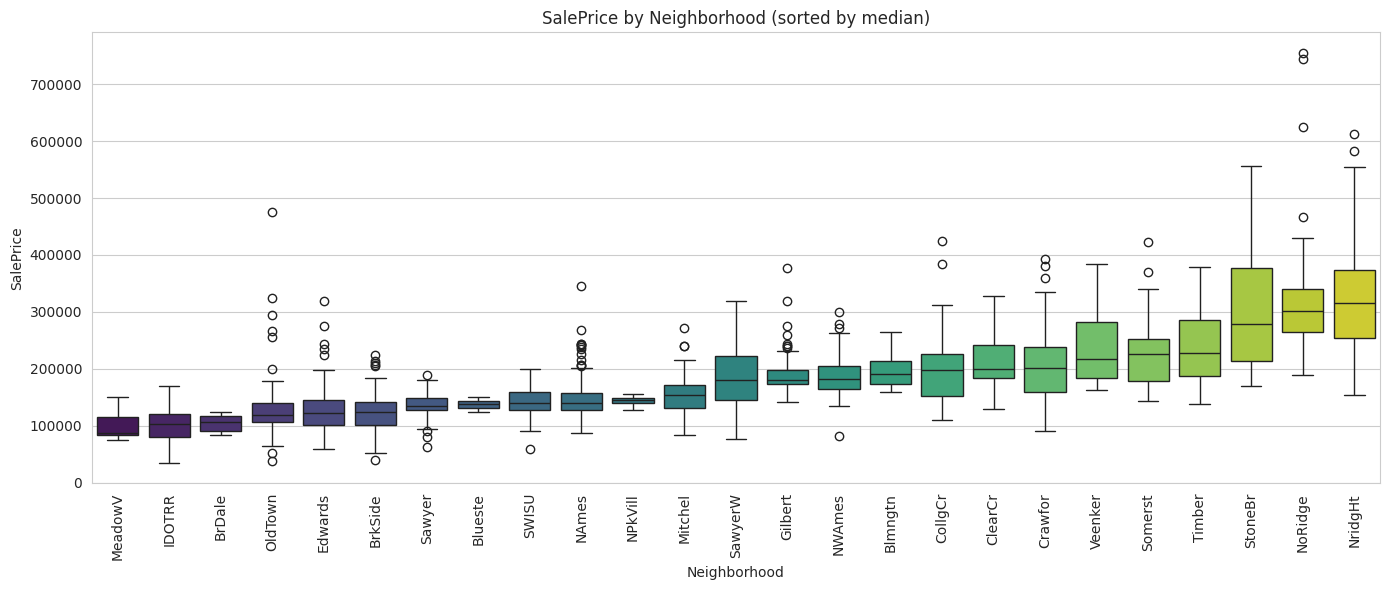

In [ ]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x='OverallQual', y='SalePrice', palette='viridis')
plt.title('SalePrice by OverallQual'); plt.show()

order_n = df.groupby('Neighborhood')['SalePrice'].median().sort_values().index
plt.figure(figsize=(14, 6))
sns.boxplot(data=df, x='Neighborhood', y='SalePrice', order=order_n, palette='viridis')
plt.xticks(rotation=90); plt.title('SalePrice by Neighborhood (sorted by median)')
plt.tight_layout(); plt.show()

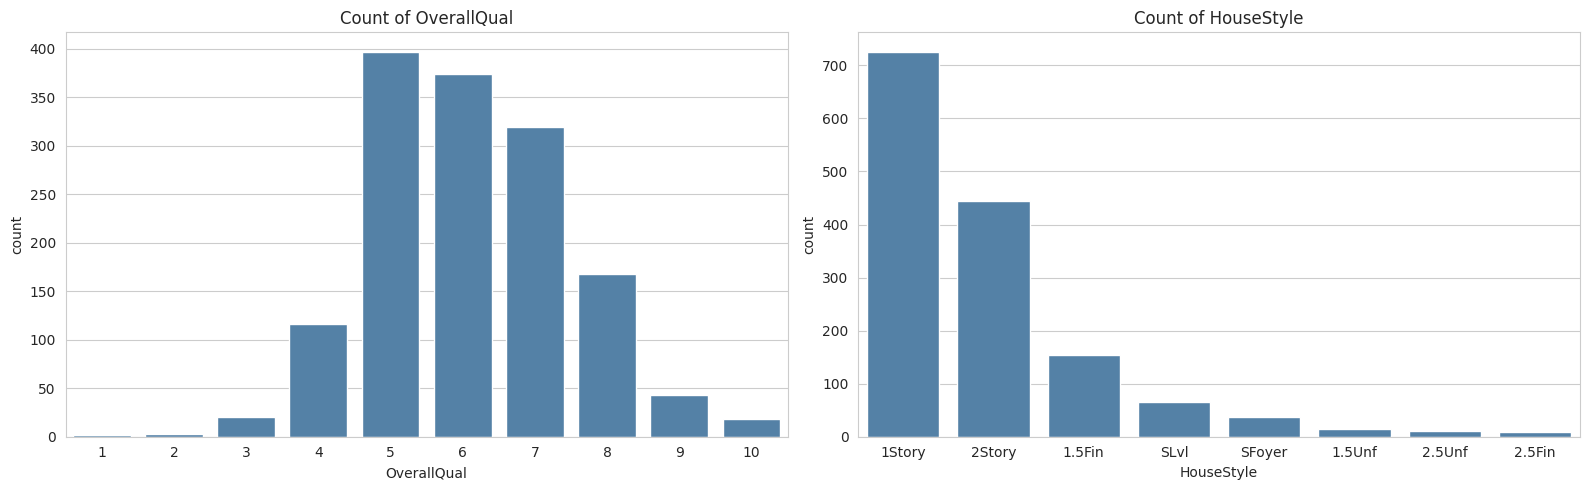

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(16, 5))
sns.countplot(data=df, x='OverallQual', ax=ax[0], color='steelblue')
ax[0].set_title('Count of OverallQual')
sns.countplot(data=df, x='HouseStyle', ax=ax[1], color='steelblue', order=df['HouseStyle'].value_counts().index)
ax[1].set_title('Count of HouseStyle')
plt.tight_layout(); plt.show()

**What I learned:** `SalePrice` is right skewed, and skewness drops from 1.881 to 0.121 after the log transform, so log(`SalePrice`) is close to normal. Price rises steadily with `OverallQual`, and the spread is much wider at the top (quality 10). Neighborhoods such as NridgHt, NoRidge and StoneBr have the highest medians (about 280k to 315k), while MeadowV, IDOTRR and BrDale are the cheapest (about 90k to 105k).

## 5. Bivariate analysis: correlation and covariance (Step 5)

In [ ]:
cov_matrix = df[numeric_cols].cov()
corr_matrix = df[numeric_cols].corr(method='pearson')

top_corr = corr_matrix['SalePrice'].abs().sort_values(ascending=False)
top10 = top_corr.index[1:11].tolist()           # skip SalePrice itself
print('Top 10 features by |correlation| with SalePrice:')
display(corr_matrix.loc[top10, 'SalePrice'].round(3))

for f in top10[:3]:
    print(f'{f:12s} covariance = {cov_matrix.loc[f, "SalePrice"]:>16,.1f} | correlation = {corr_matrix.loc[f, "SalePrice"]:.3f}')

Top 10 features by |correlation| with SalePrice:


,SalePrice
OverallQual,0.791
GrLivArea,0.709
GarageCars,0.640
GarageArea,0.623
TotalBsmtSF,0.614
1stFlrSF,0.606
FullBath,0.561
TotRmsAbvGrd,0.534
YearBuilt,0.523
YearRemodAdd,0.507


OverallQual  covariance =         86,904.1 | correlation = 0.791
GrLivArea    covariance =     29,581,866.7 | correlation = 0.709
GarageCars   covariance =         38,020.2 | correlation = 0.640


In [ ]:
# Optional: Spearman correlation (better for ordinal / monotonic relationships)
spearman = df[numeric_cols].corr(method='spearman')['SalePrice'].abs().sort_values(ascending=False)
spearman.head(11).round(3)

,SalePrice
SalePrice,1.000
OverallQual,0.810
GrLivArea,0.731
GarageCars,0.691
YearBuilt,0.653
GarageArea,0.649
FullBath,0.636
TotalBsmtSF,0.603
GarageYrBlt,0.594
1stFlrSF,0.575


**Why correlation is easier to compare than covariance:** covariance depends on the units and scale of each variable (dollars x square feet vs dollars x years), so values can't be compared across features. Correlation is standardised to the range -1 to 1.

**Correlation is not causation.** `GarageArea` and `GarageCars` are strongly correlated with each other (more cars = bigger garage). This is **multicollinearity**: they carry nearly the same information, so they shouldn't be treated as two independent drivers of price.

## 6. Scatter plots and pair plots (Step 6)

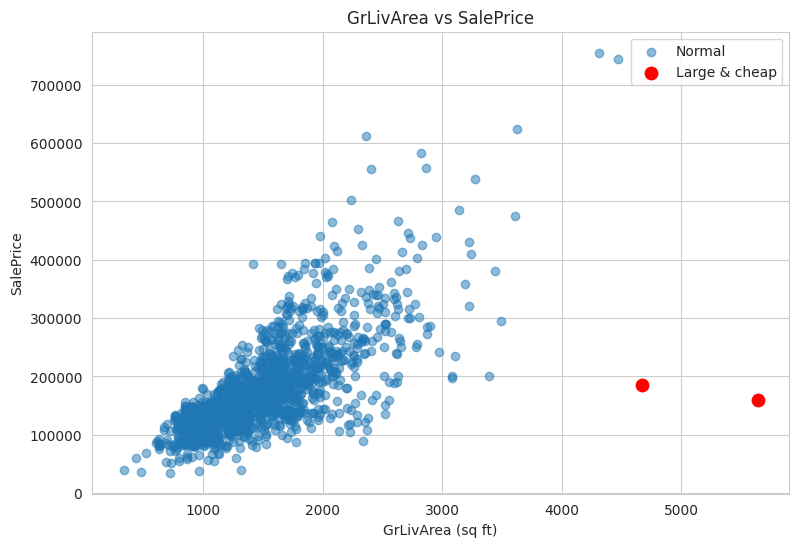

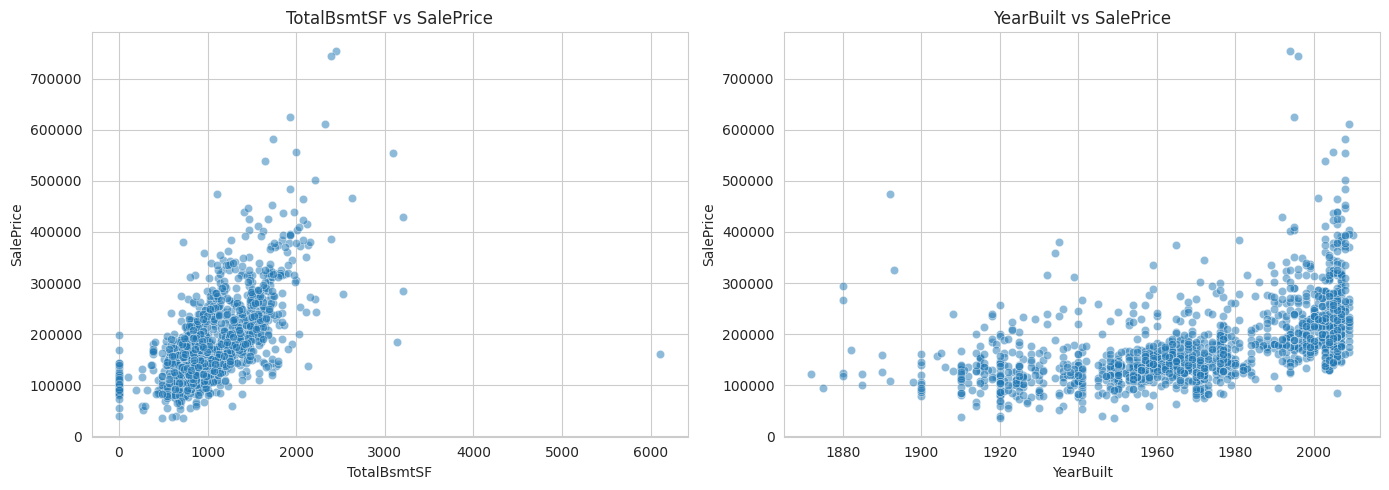

In [ ]:
flag = (df['GrLivArea'] > 4000) & (df['SalePrice'] < 300000)

plt.figure(figsize=(9, 6))
plt.scatter(df.loc[~flag, 'GrLivArea'], df.loc[~flag, 'SalePrice'], alpha=.5, label='Normal')
plt.scatter(df.loc[flag, 'GrLivArea'], df.loc[flag, 'SalePrice'], color='red', s=80, label='Large & cheap')
plt.title('GrLivArea vs SalePrice'); plt.xlabel('GrLivArea (sq ft)'); plt.ylabel('SalePrice')
plt.legend(); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(data=df, x='TotalBsmtSF', y='SalePrice', alpha=.5, ax=ax[0]).set_title('TotalBsmtSF vs SalePrice')
sns.scatterplot(data=df, x='YearBuilt', y='SalePrice', alpha=.5, ax=ax[1]).set_title('YearBuilt vs SalePrice')
plt.tight_layout(); plt.show()

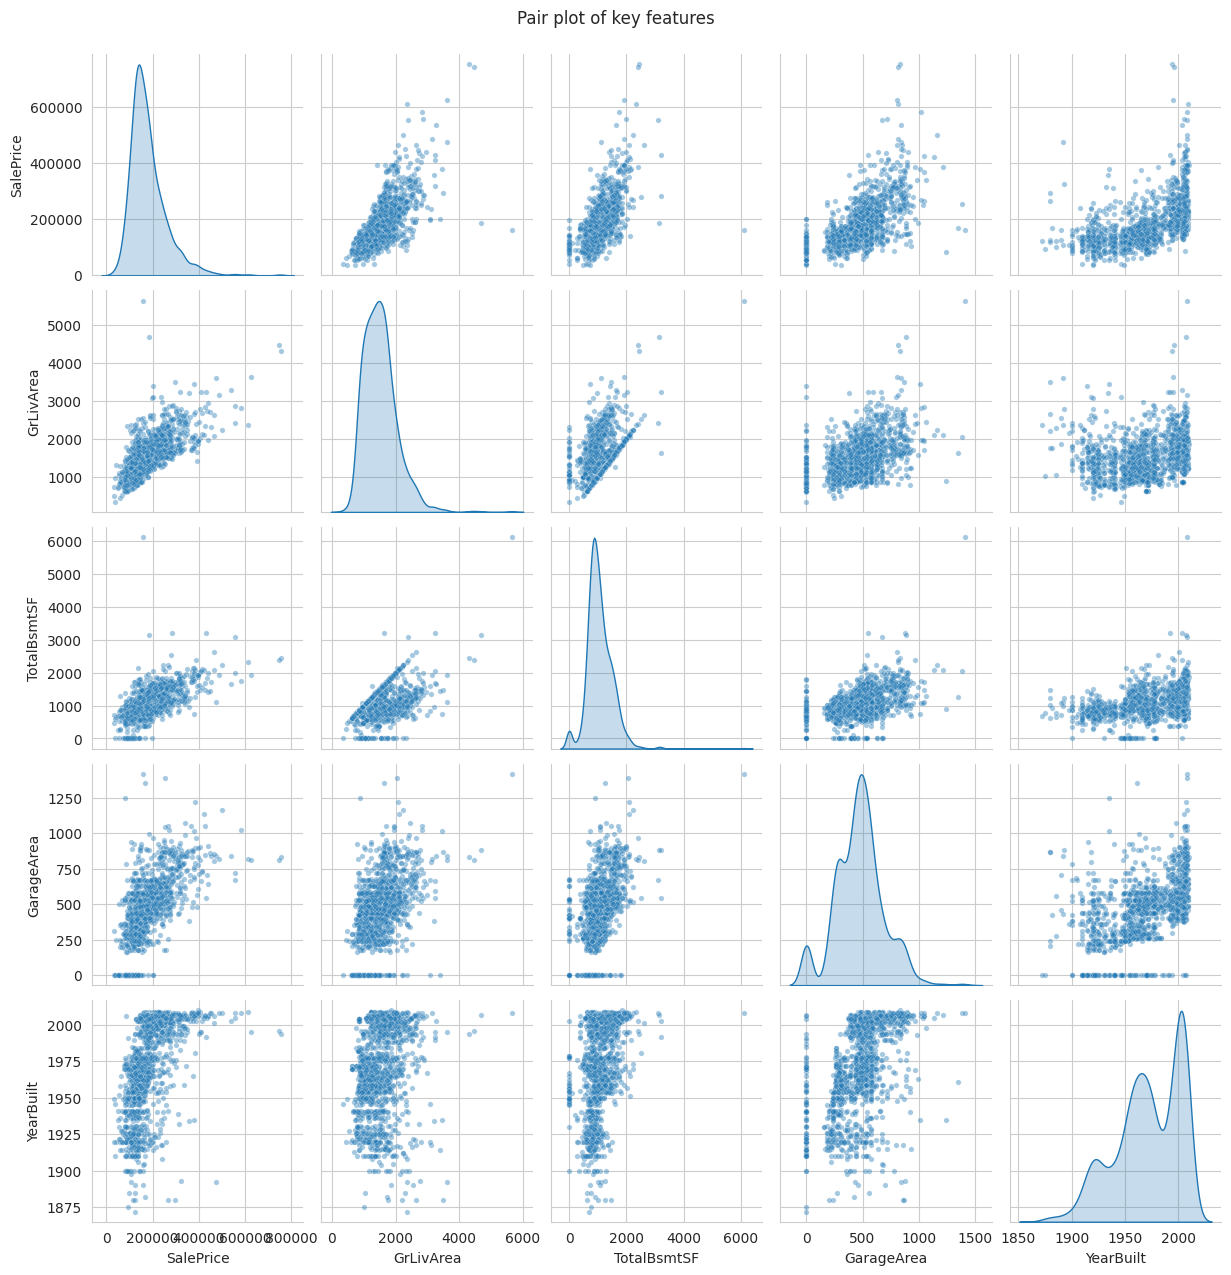

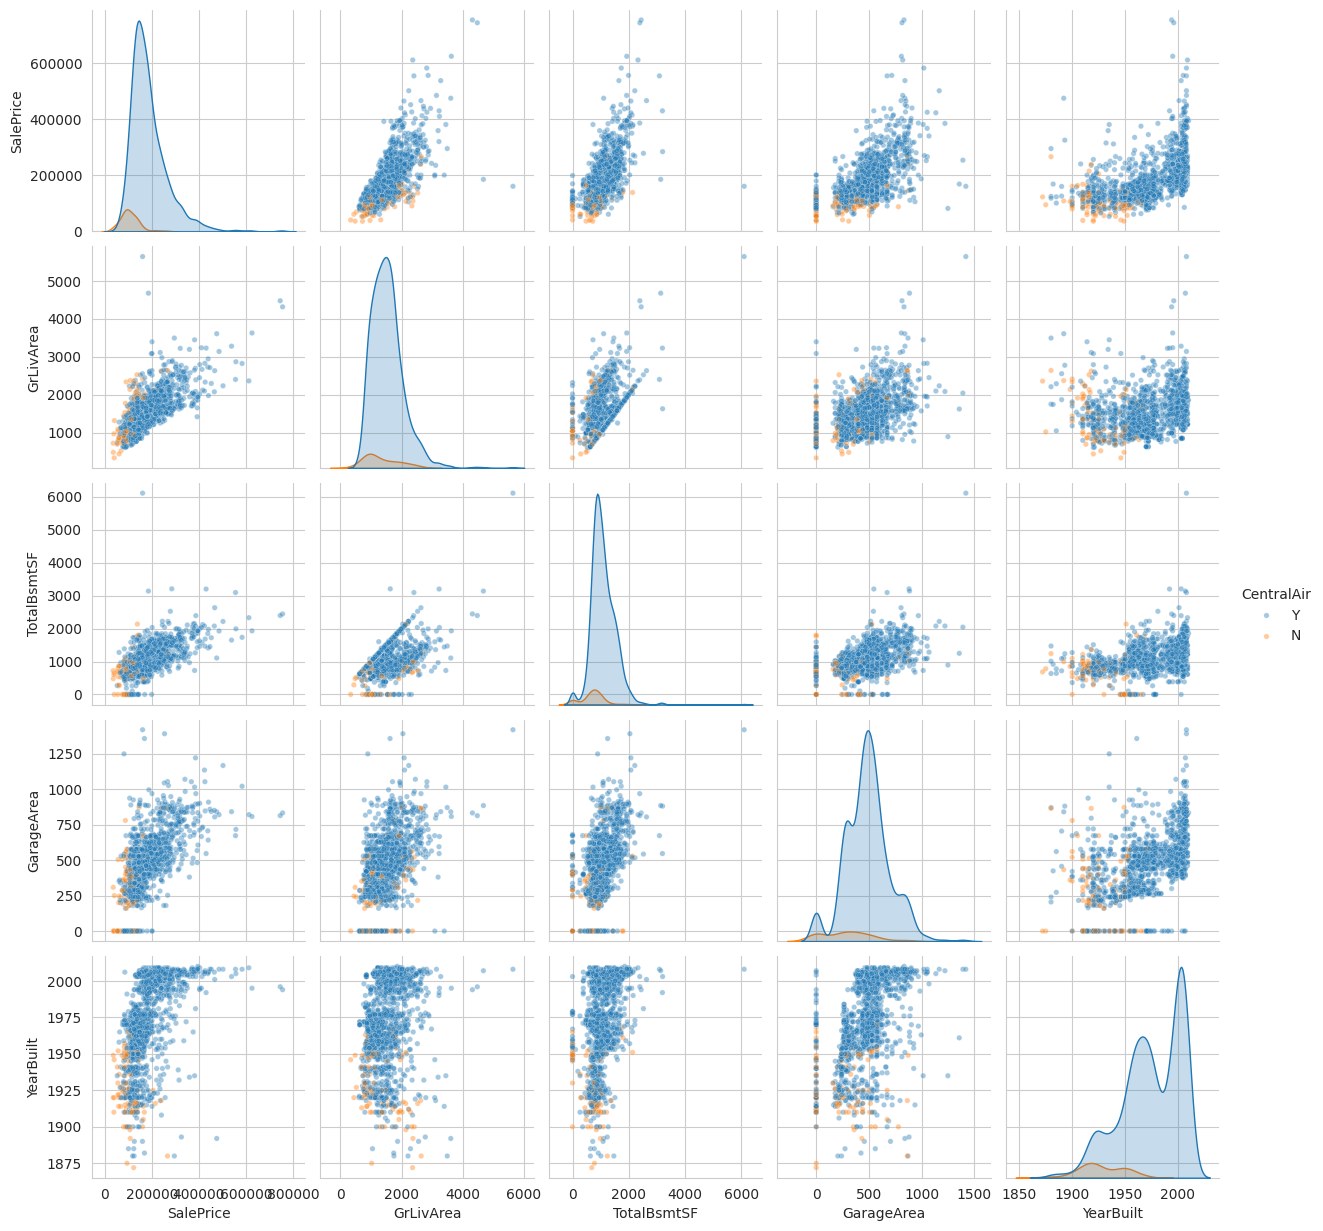

In [ ]:
selected = ['SalePrice', 'GrLivArea', 'TotalBsmtSF', 'GarageArea', 'YearBuilt']
sns.pairplot(df[selected], diag_kind='kde', plot_kws={'alpha': .4, 's': 15})
plt.suptitle('Pair plot of key features', y=1.02); plt.show()

# Optional: coloured by CentralAir
sns.pairplot(df[selected + ['CentralAir']], hue='CentralAir', diag_kind='kde', plot_kws={'alpha': .4, 's': 15})
plt.show()

## 7. Correlation heatmap (Step 7)

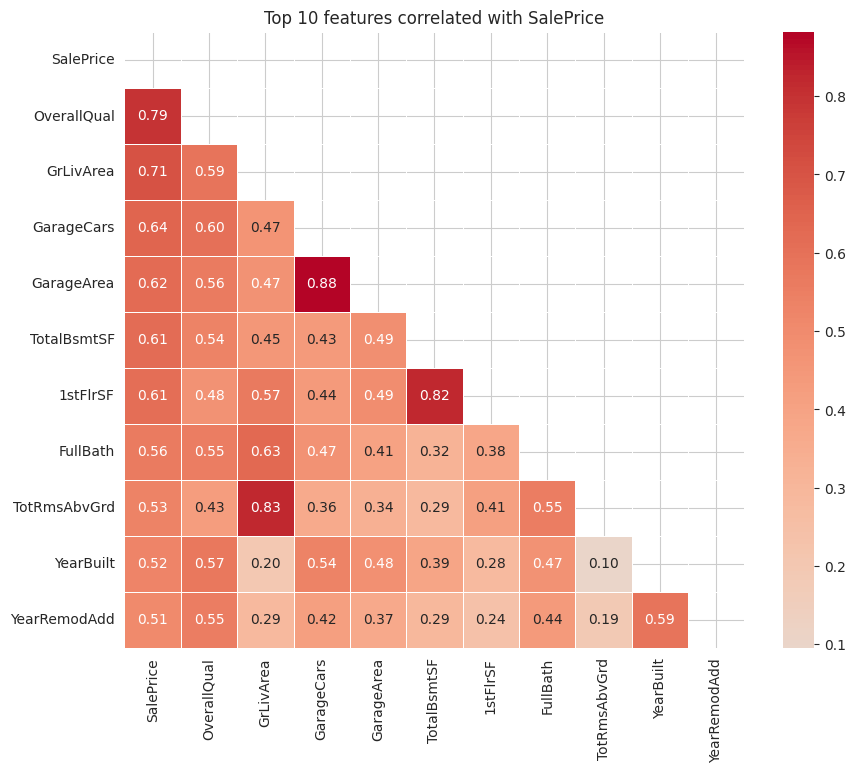

In [ ]:
cols = ['SalePrice'] + top10
corr_top = df[cols].corr()
mask = np.triu(np.ones_like(corr_top, dtype=bool))

plt.figure(figsize=(10, 8))
sns.heatmap(corr_top, mask=mask, annot=True, fmt='.2f', cmap='coolwarm', center=0, linewidths=.5)
plt.title('Top 10 features correlated with SalePrice'); plt.show()

**What I learned:** `OverallQual` (r = 0.791) and `GrLivArea` (r = 0.709) are the strongest correlates of `SalePrice`. Several top features overlap with each other, such as `GarageCars`/`GarageArea` and `TotalBsmtSF`/`1stFlrSF`, so they carry similar information and should not be treated as independent drivers of price.

## 8. Outlier analysis (Step 8)
**Doing:** detect outliers with IQR and z-score, compare, then decide what to do.

In [ ]:
def iqr_outliers(s):
    q1, q3 = s.quantile(.25), s.quantile(.75)
    iqr = q3 - q1
    return s[(s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)]

def zscore_outliers(s, threshold=3):
    z = (s - s.mean()) / s.std()
    return s[z.abs() > threshold]

for c in ['GrLivArea', 'SalePrice']:
    a, b = iqr_outliers(df[c]), zscore_outliers(df[c])
    print(f'{c}: IQR = {len(a)} | z-score = {len(b)} | overlap = {len(a.index.intersection(b.index))}')

GrLivArea: IQR = 31 | z-score = 16 | overlap = 16
SalePrice: IQR = 61 | z-score = 22 | overlap = 22


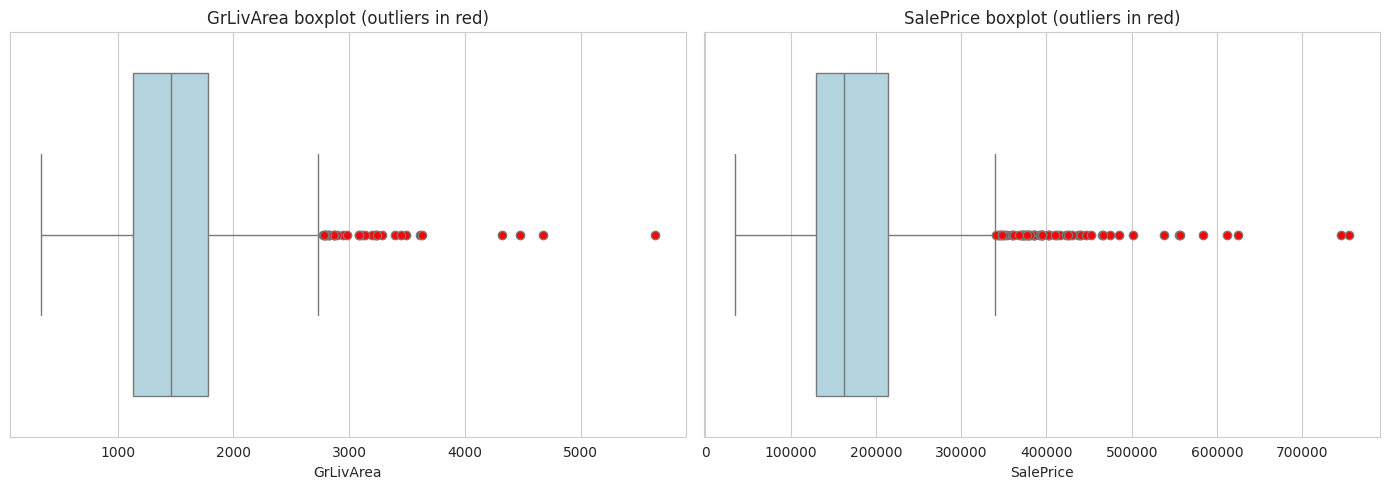

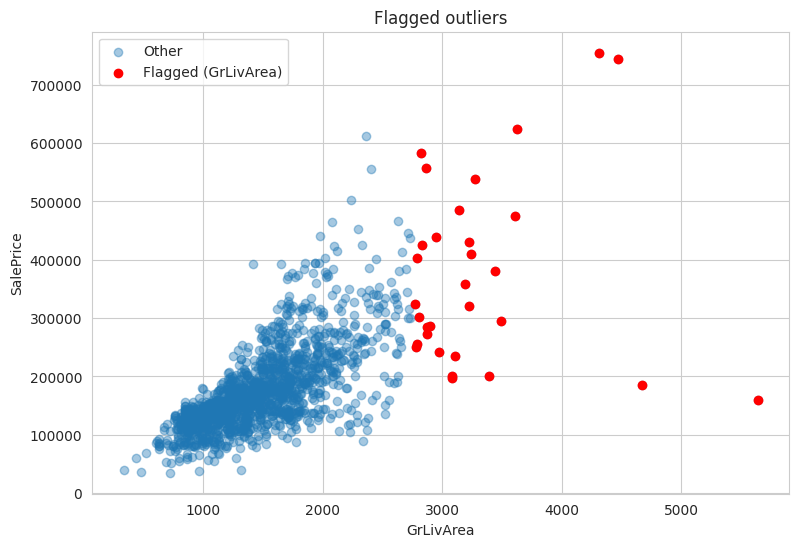

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for i, c in enumerate(['GrLivArea', 'SalePrice']):
    sns.boxplot(x=df[c], ax=ax[i], color='lightblue', flierprops={'markerfacecolor': 'red', 'marker': 'o'})
    ax[i].set_title(f'{c} boxplot (outliers in red)')
plt.tight_layout(); plt.show()

flagged = iqr_outliers(df['GrLivArea']).index.union(zscore_outliers(df['GrLivArea']).index)
plt.figure(figsize=(9, 6))
plt.scatter(df['GrLivArea'], df['SalePrice'], alpha=.4, label='Other')
plt.scatter(df.loc[flagged, 'GrLivArea'], df.loc[flagged, 'SalePrice'], color='red', label='Flagged (GrLivArea)')
plt.xlabel('GrLivArea'); plt.ylabel('SalePrice'); plt.title('Flagged outliers'); plt.legend(); plt.show()

In [ ]:
# Decision: houses > 4000 sq ft that sold cheaply are unusual sales (partial / non-typical) that distort trend lines -> remove.
# High-priced houses that are consistent with their size are real -> keep.
bad = (df['GrLivArea'] > 4000) & (df['SalePrice'] < 300000)
print('Rows removed:', bad.sum())
df_clean = df[~bad].copy()
print('df_clean shape:', df_clean.shape)
df.loc[bad, ['Id', 'GrLivArea', 'SalePrice', 'SaleCondition']]

Rows removed: 2
df_clean shape: (1458, 81)


,Id,GrLivArea,SalePrice,SaleCondition
523,524,4676,184750,Partial
1298,1299,5642,160000,Partial


**Interpretation:** The z-score method flags fewer points on a skewed variable because the mean and standard deviation are themselves inflated by the long right tail, so the threshold of 3 sits further out. The IQR method uses quartiles, which are robust to extreme values.

## 9. Data cleaning and quality checks (Step 9)
**Doing:** duplicates, inconsistent labels, 'NA means absent', filling real missing values, impossible values.

In [ ]:
# 1. Duplicates (ignoring the Id column)
dup_count = df_clean.drop(columns='Id').duplicated().sum()
print('Duplicate rows:', dup_count)
if dup_count > 0:
    df_clean = df_clean.drop_duplicates(subset=df_clean.columns.drop('Id'))
    print('New shape:', df_clean.shape)

# 2. Inconsistent categories (casing, extra spaces)
for c in categorical_cols:
    vals = df_clean[c].dropna().unique()
    cleaned = pd.Series(vals).str.strip().str.lower().nunique()
    if cleaned != len(vals):
        print('Inconsistent labels in', c, vals)
print('Category check done.')

Duplicate rows: 0
Category check done.


In [ ]:
# 3. NA = feature absent (not unknown) -> "None"
none_cols = ['PoolQC', 'MiscFeature', 'Alley', 'Fence', 'FireplaceQu', 'GarageType',
             'GarageFinish', 'GarageQual', 'GarageCond', 'BsmtQual', 'BsmtCond',
             'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2','MasVnrType']
for c in none_cols:
    df_clean[c] = df_clean[c].fillna('None')

# 4. Truly missing numeric values
df_clean['LotFrontage'] = df_clean.groupby('Neighborhood')['LotFrontage'].transform(lambda s: s.fillna(s.median()))
df_clean['LotFrontage'] = df_clean['LotFrontage'].fillna(df_clean['LotFrontage'].median())
df_clean['MasVnrArea'] = df_clean['MasVnrArea'].fillna(0)      # no veneer = 0 area
df_clean['GarageYrBlt'] = df_clean['GarageYrBlt'].fillna(0)    # no garage

# 5. Anything left: mode for categories, median for numbers
for c in df_clean.columns[df_clean.isnull().any()]:
    if pd.api.types.is_numeric_dtype(df_clean[c]):
        df_clean[c] = df_clean[c].fillna(df_clean[c].median())
    else:
        df_clean[c] = df_clean[c].fillna(df_clean[c].mode()[0])

print('Remaining missing values:', df_clean.isnull().sum().sum())

Remaining missing values: 0


In [ ]:
# 6. Impossible values
print('YearBuilt > YrSold      :', (df_clean['YearBuilt'] > df_clean['YrSold']).sum())
print('YearRemodAdd < YearBuilt:', (df_clean['YearRemodAdd'] < df_clean['YearBuilt']).sum())
area_cols = [c for c in df_clean.columns if 'SF' in c or 'Area' in c]
print('Negative areas          :', (df_clean[area_cols] < 0).sum().sum())

YearBuilt > YrSold      : 0
YearRemodAdd < YearBuilt: 0
Negative areas          : 0


**Decisions documented:**
- Columns like `PoolQC`, `Alley`, `Fence`, `FireplaceQu`, garage and basement columns: NA means *feature absent*, so filled with `"None"` rather than dropped.
- `LotFrontage`: filled with the median of its **Neighborhood** (lots in the same area are similar).
- `MasVnrArea` and `GarageYrBlt`: filled with 0 (no veneer / no garage).
- Any remaining gaps: median (numeric) or mode (categorical).

## 10. Final dashboard (Step 10)

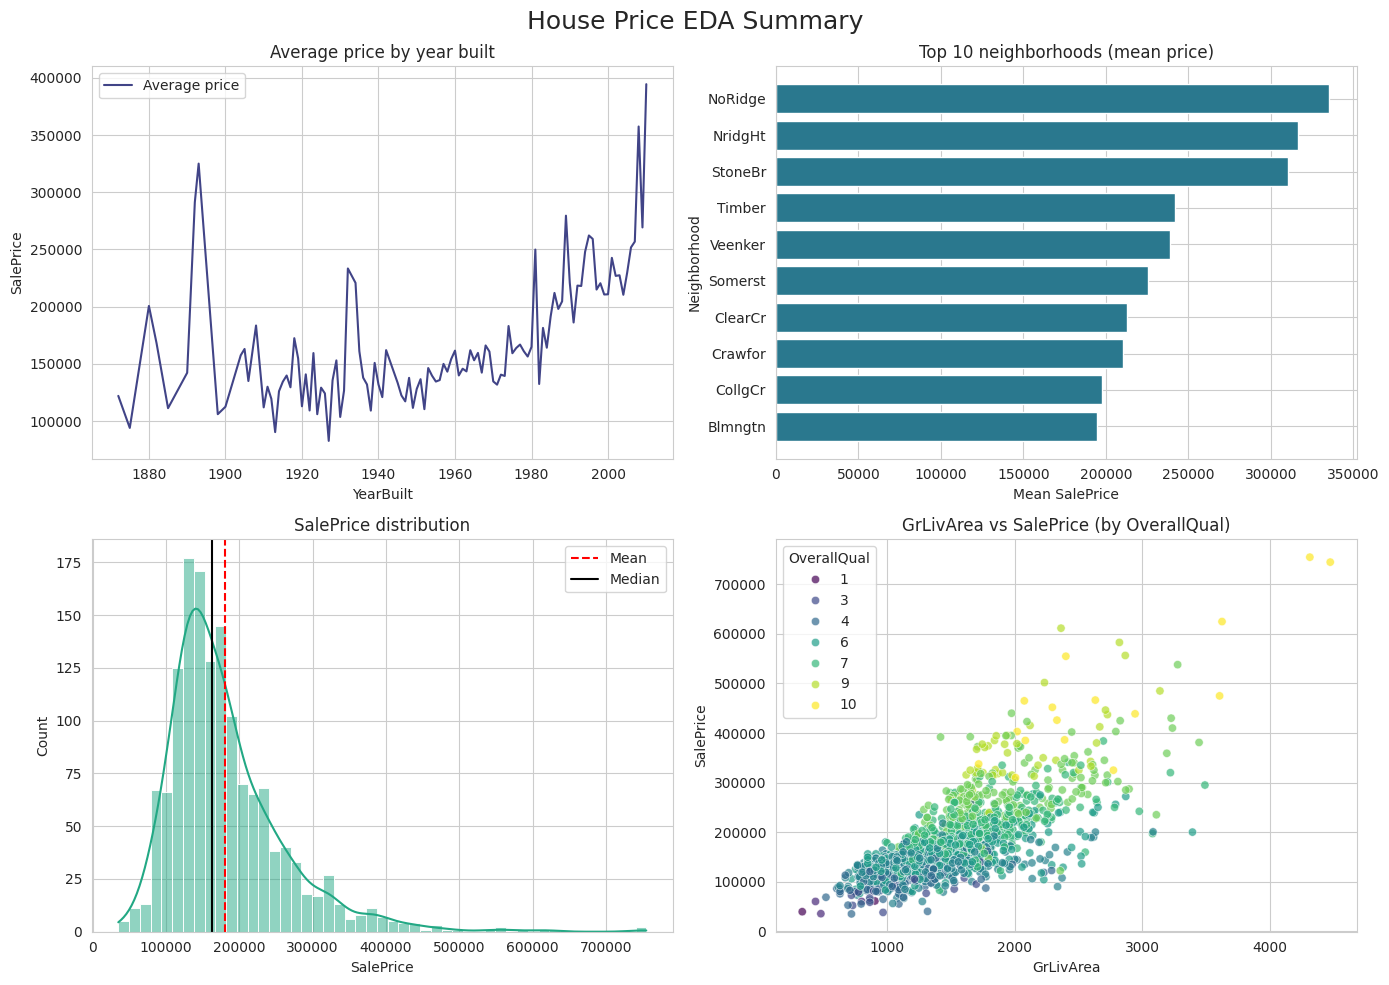

In [ ]:
palette = sns.color_palette('viridis', 4)
fig, ax = plt.subplots(2, 2, figsize=(14, 10))

# Panel 1: average price by year built
avg = df_clean.groupby('YearBuilt')['SalePrice'].mean()
ax[0, 0].plot(avg.index, avg.values, color=palette[0], label='Average price')
ax[0, 0].set(title='Average price by year built', xlabel='YearBuilt', ylabel='SalePrice'); ax[0, 0].legend()

# Panel 2: top 10 neighborhoods by mean price
top_n = df_clean.groupby('Neighborhood')['SalePrice'].mean().sort_values().tail(10)
ax[0, 1].barh(top_n.index, top_n.values, color=palette[1])
ax[0, 1].set(title='Top 10 neighborhoods (mean price)', xlabel='Mean SalePrice', ylabel='Neighborhood')

# Panel 3: distribution with mean and median
sns.histplot(df_clean['SalePrice'], kde=True, ax=ax[1, 0], color=palette[2])
ax[1, 0].axvline(df_clean['SalePrice'].mean(), color='red', ls='--', label='Mean')
ax[1, 0].axvline(df_clean['SalePrice'].median(), color='black', ls='-', label='Median')
ax[1, 0].set(title='SalePrice distribution', xlabel='SalePrice', ylabel='Count'); ax[1, 0].legend()

# Panel 4: GrLivArea vs SalePrice coloured by OverallQual
sns.scatterplot(data=df_clean, x='GrLivArea', y='SalePrice', hue='OverallQual', palette='viridis', alpha=.7, ax=ax[1, 1])
ax[1, 1].set(title='GrLivArea vs SalePrice (by OverallQual)', xlabel='GrLivArea', ylabel='SalePrice')

fig.suptitle('House Price EDA Summary', fontsize=18)
plt.tight_layout(); plt.savefig('eda_dashboard.png', dpi=150); plt.show()

In [ ]:
# Download the dashboard (Colab)
try:
    from google.colab import files; files.download('eda_dashboard.png')
except Exception: pass

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 11. Conclusions

In [ ]:
print('Skew SalePrice      :', round(stats.skew(df_clean['SalePrice']), 2))
print('Skew log(SalePrice) :', round(stats.skew(np.log(df_clean['SalePrice'])), 2))
print('Top correlates      :', top10[:3])

Skew SalePrice      : 1.88
Skew log(SalePrice) : 0.12
Top correlates      : ['OverallQual', 'GrLivArea', 'GarageCars']


### Expected insights — verified
1. `SalePrice` is right skewed; a log transform makes it close to normal.  Skewness fell from 1.881 to 0.121.
2. `OverallQual` and `GrLivArea` are among the strongest correlates of price. They rank #1 (0.791) and #2 (0.709).
3. Price rises steadily with quality, with larger spread at the top.  Median rises from ~50k (quality 1) to ~430k (quality 10), and the quality-10 IQR is ~125k versus ~40k for qualities 4 to 6.
4. A few neighborhoods (e.g. NridgHt, NoRidge, StoneBr) have clearly higher medians.Their medians are about 280k to 315k, versus about 100k to 200k for most others.
5. A handful of very large, low-priced houses are unusual sales and distort trend lines.Two houses (Id 524 and 1299) have 4,676 and 5,642 sq ft but sold for 184,750 and 160,000, and both are `SaleCondition = Partial`. They were removed.
6. Many apparent missing values are really "feature absent" and should not be dropped.`PoolQC`, `MiscFeature`, `Alley`, `Fence`, `FireplaceQu` and the garage and basement columns were filled with "None". Only `LotFrontage`, `MasVnrArea` and `Electrical` were truly missing.

### Limitations
- Only one city (Ames, Iowa) and one time window (2006 to 2010), so results may not generalise.
- Correlation does not imply causation; correlated features overlap (multicollinearity).
- Imputation choices (median, "None") are assumptions; other choices could change the numbers slightly.
- EDA only: no predictive model was built.